In [17]:
%%writefile DRL_PlayingAtariwithDeepReinforcementLearning_62.py
"""
Group 62 -- DRL Assignment I -- Proof-of-Work Implementation
Reproducing the CORE MECHANISM of Mnih et al., 2013 "Playing Atari with Deep
Reinforcement Learning" (arXiv:1312.5602) on a lightweight custom environment.

WHY NOT THE REAL ATARI PIPELINE?
The original paper trains on 10,000,000 emulator frames per game using a
GPU-accelerated convolutional network and the Arcade Learning Environment.
That is far beyond what a 2-mark-weighted course assignment can reproduce on
a laptop. Instead, we re-implement the paper's four defining algorithmic
choices from scratch, in plain NumPy (no RL library, no autodiff library),
and train them on a custom 6x6 GridWorld whose state is a one-hot "pixel
grid" (i.e. the agent gets NO hand-coded (x, y) coordinate feature -- it has
to learn spatial structure from the raw grid, exactly like DQN gets no
hand-coded game features and has to learn from raw pixels).

The four mechanisms reproduced, each directly from the paper:
  1. A neural network Q-function Q(s, a; theta) that outputs one Q-value
     per action in a single forward pass (Section 4.1).
  2. Model-free, OFF-POLICY Q-learning: the TD target bootstraps off the
     GREEDY action (max_a' Q(s', a')) while the BEHAVIOUR policy is
     epsilon-greedy (Algorithm 1 in Section 4; Eq. 1-3 in Section 2).
  3. Experience Replay: transitions (s, a, r, s') are stored in a replay
     memory D and minibatches are sampled uniformly at random to break
     temporal correlation (Section 4, Algorithm 1).
  4. RMSProp optimisation with minibatch size 32 and epsilon annealed
     linearly from 1.0 to 0.1 (Section 5, Experiments).

Run: python3 dqn_gridworld_demo.py
Outputs (written to ./outputs/):
  - training_log.txt       (full console log, timestamped)
  - reward_curve.png       (episode reward + moving average)
  - loss_curve.png         (TD loss per training step)
  - weights_summary.txt    (final network weight statistics, as a basic
                             sanity check that learning actually occurred)
"""

import numpy as np
import os
import time

OUT_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

rng = np.random.default_rng(62)  # seeded with our group number for reproducibility

# ----------------------------------------------------------------------------
# 1. ENVIRONMENT: 6x6 GridWorld, raw one-hot grid as "pixel" state
# ----------------------------------------------------------------------------
GRID_N = 6
N_STATES = GRID_N * GRID_N
N_ACTIONS = 4  # up, down, left, right
GOAL = (GRID_N - 1, GRID_N - 1)
MAX_STEPS = 40


class GridWorld:
    """Minimal control task standing in for the Atari emulator. The agent
    observes a flattened one-hot grid (its own position only) -- analogous
    to DQN's raw-pixel input: no privileged coordinate feature is given."""

    def __init__(self):
        self.pos = (0, 0)
        self.steps = 0

    def reset(self):
        self.pos = (0, 0)
        self.steps = 0
        return self._obs()

    def _obs(self):
        grid = np.zeros((GRID_N, GRID_N), dtype=np.float32)
        grid[self.pos] = 1.0
        return grid.flatten()

    def step(self, action):
        r, c = self.pos
        if action == 0:   r = max(0, r - 1)       # up
        elif action == 1: r = min(GRID_N - 1, r + 1)  # down
        elif action == 2: c = max(0, c - 1)       # left
        elif action == 3: c = min(GRID_N - 1, c + 1)  # right
        self.pos = (r, c)
        self.steps += 1

        done = self.pos == GOAL or self.steps >= MAX_STEPS
        if self.pos == GOAL:
            reward = 1.0
        else:
            reward = -0.02  # small per-step penalty encourages shortest paths
        # Reward clipping to {-1, 0, +1}, as in the paper's Section 5,
        # so one learning rate can suit any reward scale.
        reward = float(np.clip(reward, -1.0, 1.0))
        return self._obs(), reward, done


# ----------------------------------------------------------------------------
# 2. Q-NETWORK: plain-NumPy 2-layer MLP, manual forward + backward pass
#    (stands in for the paper's CNN -- same role: raw state in, one Q-value
#    per action out, in a single forward pass)
# ----------------------------------------------------------------------------
HIDDEN = 64


class QNetwork:
    def __init__(self):
        scale1 = np.sqrt(2.0 / N_STATES)
        scale2 = np.sqrt(2.0 / HIDDEN)
        self.W1 = rng.normal(0, scale1, (N_STATES, HIDDEN)).astype(np.float32)
        self.b1 = np.zeros(HIDDEN, dtype=np.float32)
        self.W2 = rng.normal(0, scale2, (HIDDEN, N_ACTIONS)).astype(np.float32)
        self.b2 = np.zeros(N_ACTIONS, dtype=np.float32)
        # RMSProp caches (Mnih et al., Section 5: "RMSProp... minibatches of size 32")
        self.cache = {k: np.zeros_like(v) for k, v in self._params().items()}

    def _params(self):
        return {"W1": self.W1, "b1": self.b1, "W2": self.W2, "b2": self.b2}

    def forward(self, x):
        z1 = x @ self.W1 + self.b1
        h = np.maximum(0, z1)  # ReLU, matching the paper's rectifier nonlinearities
        q = h @ self.W2 + self.b2
        return q, (x, z1, h)

    def backward(self, cache_tuple, grad_q):
        x, z1, h = cache_tuple
        batch = x.shape[0]
        dW2 = h.T @ grad_q / batch
        db2 = grad_q.mean(axis=0)
        dh = grad_q @ self.W2.T
        dz1 = dh * (z1 > 0)
        dW1 = x.T @ dz1 / batch
        db1 = dz1.mean(axis=0)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def rmsprop_update(self, grads, lr=0.001, decay=0.95, eps=1e-6):
        params = self._params()
        for k in params:
            self.cache[k] = decay * self.cache[k] + (1 - decay) * (grads[k] ** 2)
            params[k] -= lr * grads[k] / (np.sqrt(self.cache[k]) + eps)


# ----------------------------------------------------------------------------
# 3. EXPERIENCE REPLAY (Section 4 and Algorithm 1 of the paper)
# ----------------------------------------------------------------------------
class ReplayMemory:
    def __init__(self, capacity=5000):
        self.capacity = capacity
        self.buffer = []
        self.pos = 0

    def push(self, transition):
        if len(self.buffer) < self.capacity:
            self.buffer.append(transition)
        else:
            self.buffer[self.pos] = transition
            self.pos = (self.pos + 1) % self.capacity

    def sample(self, batch_size):
        idx = rng.integers(0, len(self.buffer), size=batch_size)
        batch = [self.buffer[i] for i in idx]
        s, a, r, s2, done = zip(*batch)
        return (np.array(s, dtype=np.float32), np.array(a, dtype=np.int64),
                np.array(r, dtype=np.float32), np.array(s2, dtype=np.float32),
                np.array(done, dtype=np.float32))

    def __len__(self):
        return len(self.buffer)


# ----------------------------------------------------------------------------
# 4. TRAINING LOOP -- mirrors Algorithm 1 in the paper
# ----------------------------------------------------------------------------
def train(n_episodes=400, batch_size=32, gamma=0.95,
          eps_start=1.0, eps_end=0.1, eps_anneal_episodes=250):
    env = GridWorld()
    net = QNetwork()
    memory = ReplayMemory(capacity=5000)

    episode_rewards = []
    losses = []
    log_lines = []

    def log(msg):
        print(msg)
        log_lines.append(msg)

    log("=" * 70)
    log("Group 62 -- DQN-style training run (custom GridWorld, NumPy-only)")
    log(f"Started: {time.strftime('%Y-%m-%d %H:%M:%S')}")
    log(f"Config: episodes={n_episodes}, batch_size={batch_size}, gamma={gamma}, "
        f"eps {eps_start}->{eps_end} over {eps_anneal_episodes} episodes")
    log("=" * 70)

    for ep in range(n_episodes):
        # Linear epsilon annealing -- "annealed linearly from 1.0 to 0.1
        # over the first million frames" (paper, Section 5) -- scaled here
        # to our much smaller episode budget.
        eps = max(eps_end, eps_start - (eps_start - eps_end) * (ep / eps_anneal_episodes))

        s = env.reset()
        total_reward = 0.0
        done = False
        while not done:
            if rng.random() < eps:
                a = rng.integers(0, N_ACTIONS)
            else:
                q, _ = net.forward(s[None, :])
                a = int(np.argmax(q[0]))

            s2, r, done = env.step(a)
            memory.push((s, a, r, s2, float(done)))
            total_reward += r
            s = s2

            if len(memory) >= batch_size:
                sb, ab, rb, s2b, doneb = memory.sample(batch_size)
                q_next, _ = net.forward(s2b)
                target = rb + gamma * np.max(q_next, axis=1) * (1 - doneb)

                q_pred, cache = net.forward(sb)
                q_sa = q_pred[np.arange(batch_size), ab]
                td_error = q_sa - target
                loss = np.mean(td_error ** 2)
                losses.append(loss)

                grad_q = np.zeros_like(q_pred)
                grad_q[np.arange(batch_size), ab] = 2 * td_error / batch_size
                grads = net.backward(cache, grad_q)
                net.rmsprop_update(grads)

        episode_rewards.append(total_reward)

        if (ep + 1) % 25 == 0 or ep == 0:
            recent = np.mean(episode_rewards[-25:])
            avg_loss = np.mean(losses[-200:]) if losses else float("nan")
            log(f"Episode {ep+1:4d}/{n_episodes} | eps={eps:.3f} | "
                f"reward={total_reward:+.3f} | avg(last25)={recent:+.3f} | "
                f"avg_td_loss={avg_loss:.5f} | replay_size={len(memory)}")

    log("=" * 70)
    log(f"Finished: {time.strftime('%Y-%m-%d %H:%M:%S')}")
    final_success = np.mean([1.0 if r > 0 else 0.0 for r in episode_rewards[-50:]])
    log(f"Success rate, final 50 episodes (reached goal): {final_success*100:.1f}%")
    log(f"Mean reward, first 25 episodes : {np.mean(episode_rewards[:25]):+.3f}")
    log(f"Mean reward, final 25 episodes : {np.mean(episode_rewards[-25:]):+.3f}")
    log("=" * 70)

    with open(os.path.join(OUT_DIR, "training_log.txt"), "w") as f:
        f.write("\n".join(log_lines))

    with open(os.path.join(OUT_DIR, "weights_summary.txt"), "w") as f:
        f.write("Final network weight statistics (sanity check that learning occurred)\n")
        for k, v in net._params().items():
            f.write(f"{k}: shape={v.shape}, mean={v.mean():.5f}, std={v.std():.5f}\n")

    return episode_rewards, losses, final_success


if __name__ == "__main__":
    rewards, losses, success = train()

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    # --- Reward curve ---
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(rewards, color="#CADCFC", linewidth=1, label="Episode reward")
    window = 20
    if len(rewards) >= window:
        moving_avg = np.convolve(rewards, np.ones(window) / window, mode="valid")
        ax.plot(range(window - 1, len(rewards)), moving_avg, color="#1E2761",
                 linewidth=2.5, label=f"{window}-episode moving average")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Total episode reward")
    ax.set_title("Group 62 — Training Reward Curve (custom DQN-style agent)")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "reward_curve.png"), dpi=160)

    # --- Loss curve ---
    fig2, ax2 = plt.subplots(figsize=(8, 4.5))
    ax2.plot(losses, color="#F2A900", linewidth=0.8)
    ax2.set_xlabel("Training (SGD) step")
    ax2.set_ylabel("TD loss  (y_j - Q(s,a;θ))²")
    ax2.set_title("Group 62 — Q-Learning TD Loss per Minibatch Update")
    ax2.grid(alpha=0.3)
    fig2.tight_layout()
    fig2.savefig(os.path.join(OUT_DIR, "loss_curve.png"), dpi=160)

    print(f"\nFinal goal-reach success rate (last 50 episodes): {success*100:.1f}%")
    print(f"Outputs written to: {OUT_DIR}")

Overwriting DRL_PlayingAtariwithDeepReinforcementLearning_62.py


## 1. Train the agent
Prints the training log and writes `outputs/` (log, reward curve, loss curve, weight summary).

In [18]:
!python3 DRL_PlayingAtariwithDeepReinforcementLearning_62.py

Group 62 -- DQN-style training run (custom GridWorld, NumPy-only)
Started: 2026-10-11 14:23:53
Config: episodes=400, batch_size=32, gamma=0.95, eps 1.0->0.1 over 250 episodes
Episode    1/400 | eps=1.000 | reward=+0.460 | avg(last25)=+0.460 | avg_td_loss=nan | replay_size=28
Episode   25/400 | eps=0.914 | reward=-0.800 | avg(last25)=-0.550 | avg_td_loss=0.00771 | replay_size=943
Episode   50/400 | eps=0.824 | reward=+0.220 | avg(last25)=-0.166 | avg_td_loss=0.00766 | replay_size=1763
Episode   75/400 | eps=0.734 | reward=+0.460 | avg(last25)=-0.208 | avg_td_loss=0.00786 | replay_size=2584
Episode  100/400 | eps=0.644 | reward=+0.820 | avg(last25)=+0.131 | avg_td_loss=0.00841 | replay_size=3338
Episode  125/400 | eps=0.554 | reward=+0.260 | avg(last25)=+0.533 | avg_td_loss=0.00652 | replay_size=3896
Episode  150/400 | eps=0.464 | reward=+0.700 | avg(last25)=+0.578 | avg_td_loss=0.00669 | replay_size=4398
Episode  175/400 | eps=0.374 | reward=+0.820 | avg(last25)=+0.699 | avg_td_loss=0.0

## 2. Sanity check against the optimal return
On the 6x6 grid the shortest path from (0,0) to (5,5) is 10 steps: nine step penalties of -0.02, then +1.0 at the goal. A per-episode reward of +0.82 therefore means the agent found a shortest path. The moving average sits slightly below it because epsilon stays at 0.1 (some random moves).

In [19]:
optimal_return = 9 * (-0.02) + 1.0
print(f"Optimal episode return = {optimal_return:.3f}")
print()
print(open('outputs/weights_summary.txt').read())

Optimal episode return = 0.820

Final network weight statistics (sanity check that learning occurred)
W1: shape=(36, 64), mean=0.04148, std=0.27597
b1: shape=(64,), mean=-0.09523, std=0.09629
W2: shape=(64, 4), mean=0.13332, std=0.14982
b2: shape=(4,), mean=-0.10598, std=0.02509



## 3. Learning curves generated by this run

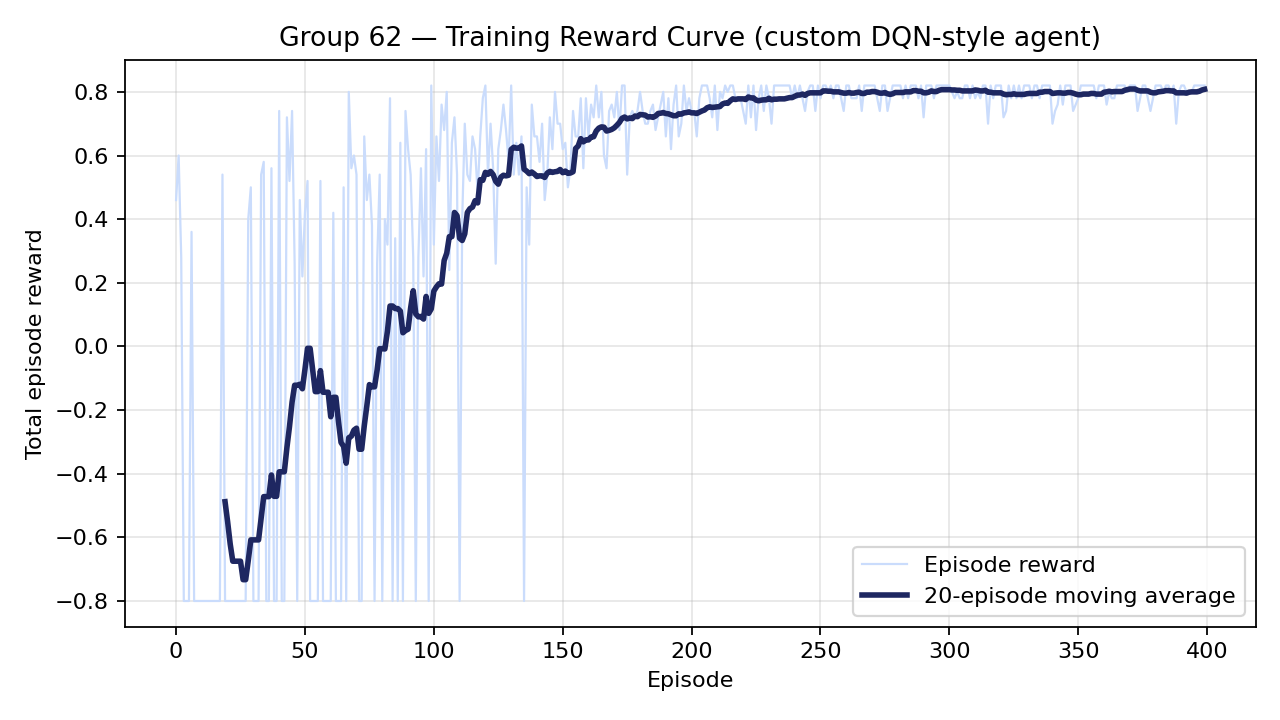

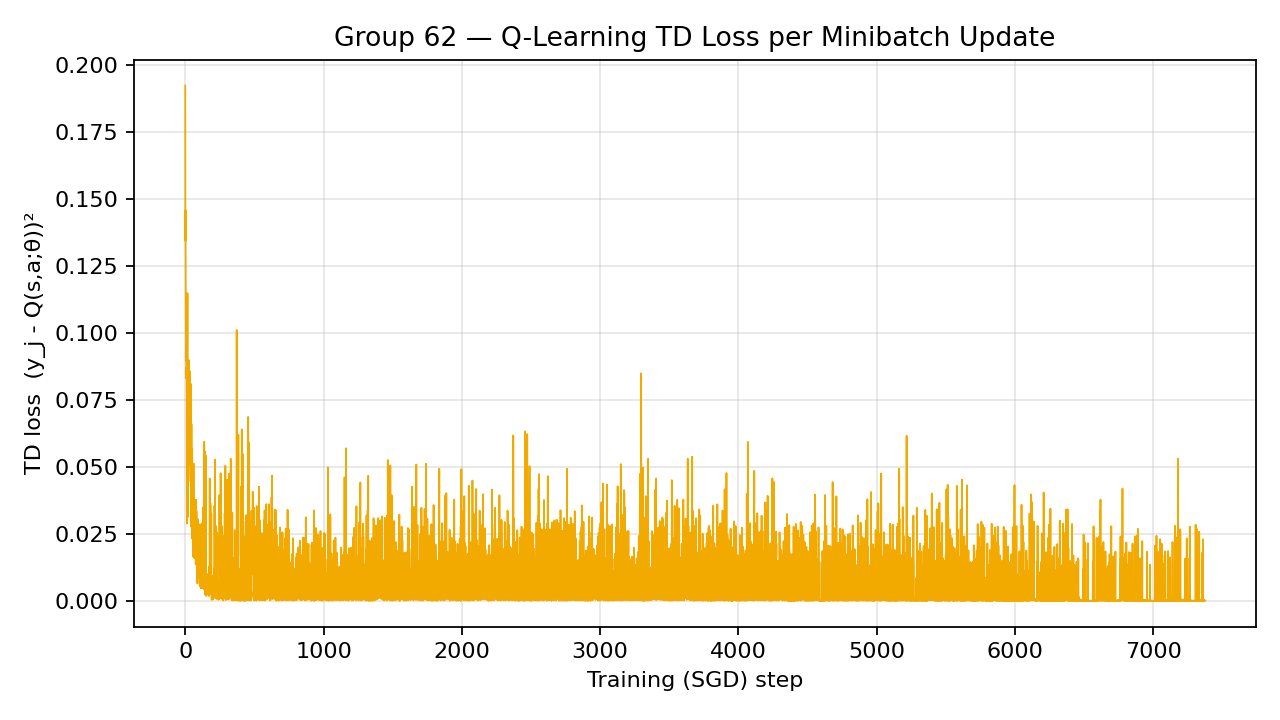

In [20]:
from IPython.display import Image, display
display(Image('outputs/reward_curve.png'))
display(Image('outputs/loss_curve.png'))